In [35]:
pip install pandas numpy scikit-learn matplotlib seaborn jupyter


In [36]:
import pandas as pd

In [37]:
import numpy as np

In [38]:
import sklearn


In [39]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

# Preview the dataset
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nSpecies distribution:")
print(df["species"].value_counts())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Dataset shape: (150, 5)

Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [40]:
X = df.drop(columns=["species"])

In [41]:
y = df["species"]

In [42]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["species"])
y = df["species"]

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Train/test split completed successfully!")

Training samples: 120
Testing samples: 30
Train/test split completed successfully!


In [43]:
X = df.drop(columns=["species"])

# Target labels
y = df["species"]

# Split into training and testing data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

# Check data types and missing values
print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Statistical summary:


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


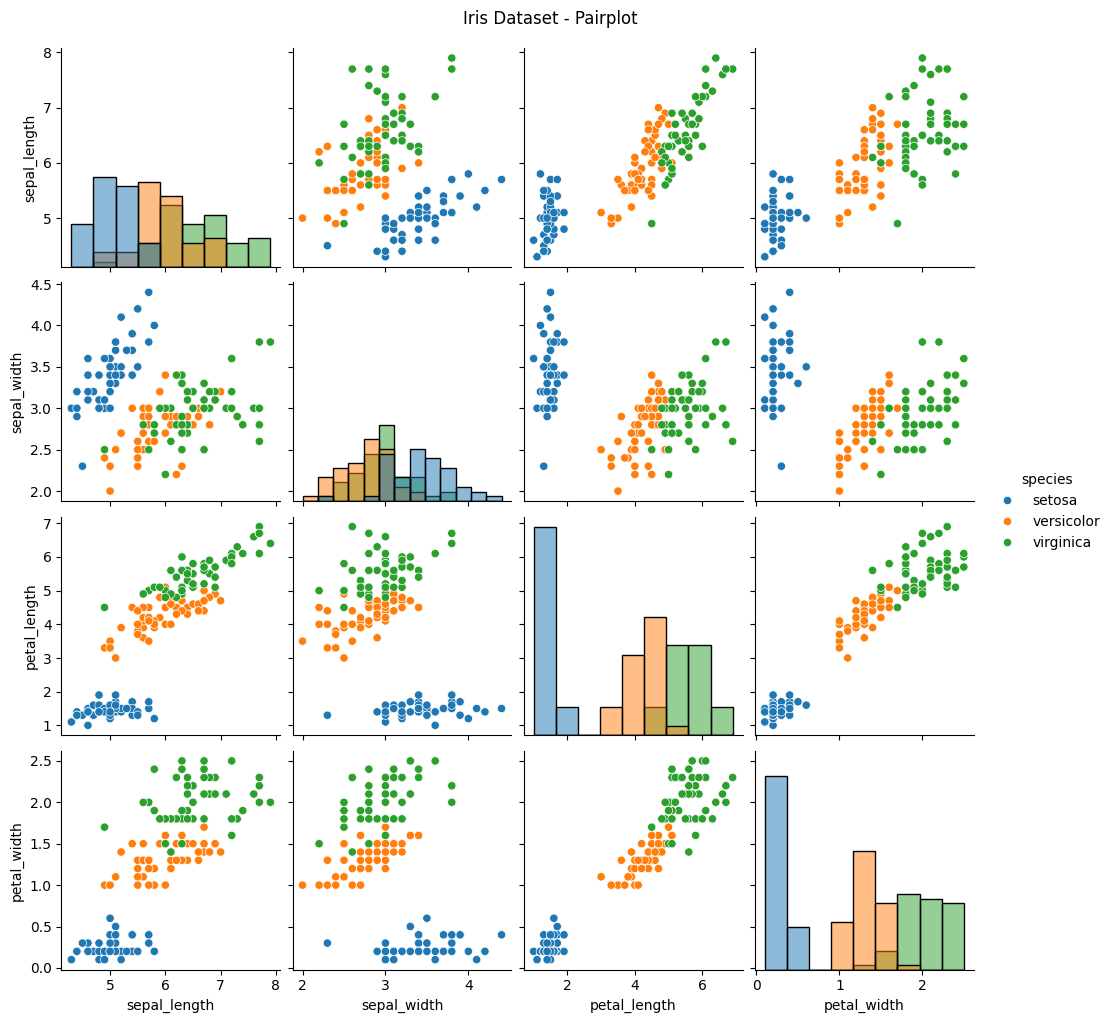

In [45]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

In [46]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Feature scaling completed!
Scaled training shape: (120, 4)
Scaled testing shape: (30, 4)


In [48]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

predictions = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions[name] = model.predict(X_test_scaled)
    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!


In [49]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for name, model in models.items():
    y_pred = predictions[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


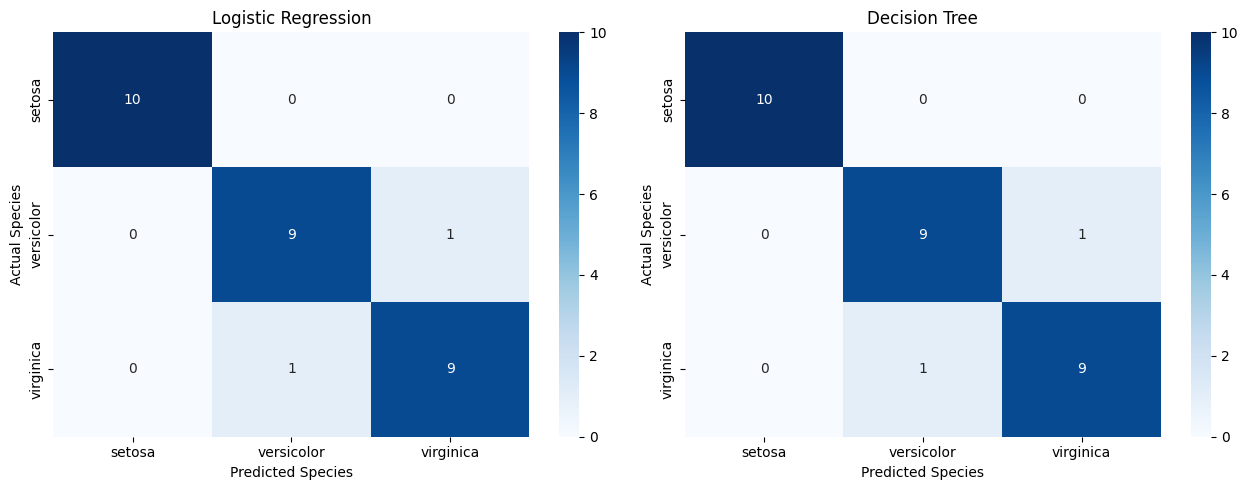

In [50]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

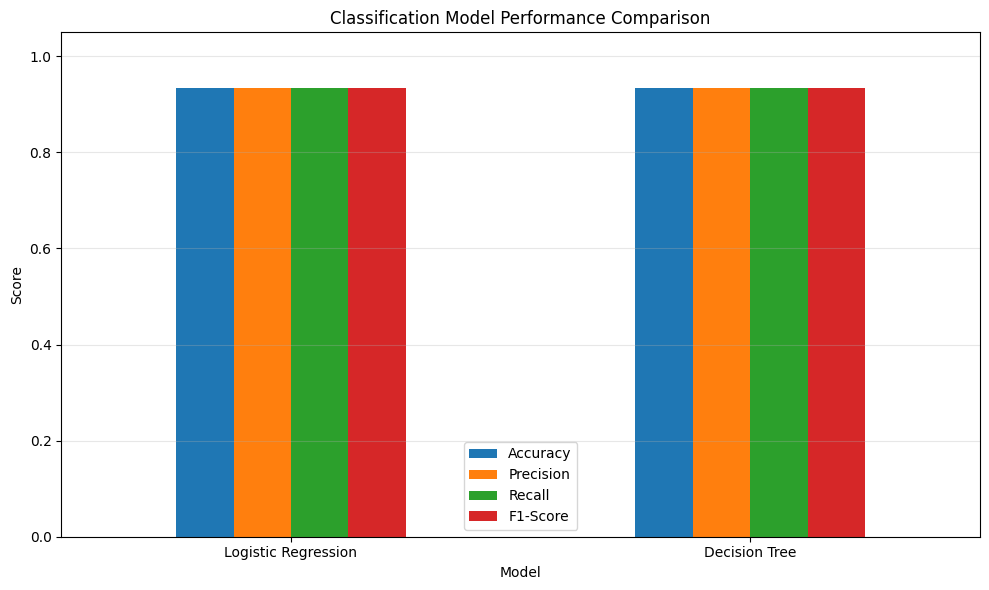

In [51]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.05),
    rot=0
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

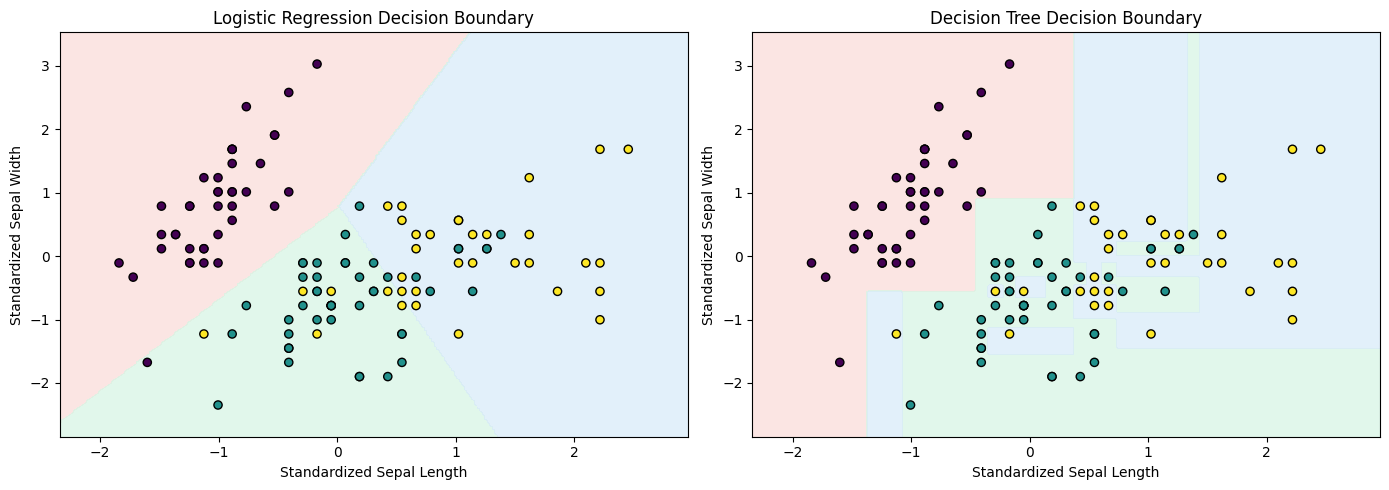

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Select two numerical features
X_2d = df[["sepal_length", "sepal_width"]].to_numpy(dtype=float)
y_2d = df["species"].astype(str).to_numpy()

# Convert species names to numeric labels for plotting
species_names = sorted(np.unique(y_2d))
label_map = {name: i for i, name in enumerate(species_names)}
y_numeric = np.array([label_map[label] for label in y_2d])

# Split dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_numeric,
    test_size=0.2,
    random_state=42,
    stratify=y_numeric
)

# Scale the training features
scaler_2d = StandardScaler()
X2_train_scaled = scaler_2d.fit_transform(X2_train)

# Train models using two features
models_2d = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

for model in models_2d.values():
    model.fit(X2_train_scaled, y2_train)

# Generate the mesh grid
x_min = X2_train_scaled[:, 0].min() - 0.5
x_max = X2_train_scaled[:, 0].max() + 0.5
y_min = X2_train_scaled[:, 1].min() - 0.5
y_max = X2_train_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]

# Explicit numeric colors
background_colors = ListedColormap(
    ["#FADBD8", "#D5F5E3", "#D6EAF8"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, model) in zip(axes, models_2d.items()):
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5, 2.5],
        cmap=background_colors,
        alpha=0.7
    )

    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=y2_train,
        cmap="viridis",
        edgecolors="black",
        s=35
    )

    ax.set_title(f"{name} Decision Boundary")
    ax.set_xlabel("Standardized Sepal Length")
    ax.set_ylabel("Standardized Sepal Width")

plt.tight_layout()
plt.show()

In [53]:
print(df.columns.tolist())

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [54]:
results_df.to_csv("classification_results.csv", index=False)
print("Results saved successfully!")

Results saved successfully!


In [55]:
from google.colab import files
files.download("classification_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
from sklearn.metrics import classification_report

for name, model in models.items():
    print(f"\n===== {name} =====")
    print(classification_report(
        y_test,
        predictions[name],
        zero_division=0
    ))


===== Logistic Regression =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


===== Decision Tree =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [57]:
best_model = results_df.loc[
    results_df["F1-Score"].idxmax()
]

print("Best model based on macro F1-score:")
print(best_model["Model"])
print("\nPerformance:")
print(best_model)

Best model based on macro F1-score:
Logistic Regression

Performance:
Model        Logistic Regression
Accuracy                0.933333
Precision               0.933333
Recall                  0.933333
F1-Score                0.933333
Name: 0, dtype: object


In [58]:
# Example measurements:
# sepal length, sepal width, petal length, petal width
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=X.columns
)

# Scale with the existing fitted scaler
new_flower_scaled = scaler.transform(new_flower)

for name, model in models.items():
    prediction = model.predict(new_flower_scaled)
    print(f"{name} prediction: {prediction[0]}")

Logistic Regression prediction: setosa
Decision Tree prediction: setosa


### Conclusion

The Iris dataset was used to build a supervised multi-class classification pipeline using Scikit-Learn. Data exploration, feature scaling, and an 80:20 train-test split were performed. Logistic Regression and Decision Tree classifiers were trained and evaluated using accuracy, precision, recall, and F1-score. Confusion matrices, model comparison charts, and decision boundary visualizations were used to analyze model performance. Both models were also tested on a new flower sample. This project demonstrates the application of machine learning classification techniques to predict flower species.